In [1]:
import pandas as pd

calendar = pd.read_csv("../data/raw/calendar.csv")
sales = pd.read_csv("../data/raw/sales_train_evaluation.csv")
prices = pd.read_csv("../data/raw/sell_prices.csv")

print("Calendar:", calendar.shape)
print("Sales:", sales.shape)
print("Prices:", prices.shape)

Calendar: (1969, 14)
Sales: (30490, 1947)
Prices: (6841121, 4)


In [2]:
display(calendar.head())
display(sales.head())
display(prices.head())

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [3]:
print(calendar.columns.tolist())
print(sales.columns.tolist())
print(prices.columns.tolist())

['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9', 'd_10', 'd_11', 'd_12', 'd_13', 'd_14', 'd_15', 'd_16', 'd_17', 'd_18', 'd_19', 'd_20', 'd_21', 'd_22', 'd_23', 'd_24', 'd_25', 'd_26', 'd_27', 'd_28', 'd_29', 'd_30', 'd_31', 'd_32', 'd_33', 'd_34', 'd_35', 'd_36', 'd_37', 'd_38', 'd_39', 'd_40', 'd_41', 'd_42', 'd_43', 'd_44', 'd_45', 'd_46', 'd_47', 'd_48', 'd_49', 'd_50', 'd_51', 'd_52', 'd_53', 'd_54', 'd_55', 'd_56', 'd_57', 'd_58', 'd_59', 'd_60', 'd_61', 'd_62', 'd_63', 'd_64', 'd_65', 'd_66', 'd_67', 'd_68', 'd_69', 'd_70', 'd_71', 'd_72', 'd_73', 'd_74', 'd_75', 'd_76', 'd_77', 'd_78', 'd_79', 'd_80', 'd_81', 'd_82', 'd_83', 'd_84', 'd_85', 'd_86', 'd_87', 'd_88', 'd_89', 'd_90', 'd_91', 'd_92', 'd_93', 'd_94', 'd_95', 'd_96', 'd_97', 'd_98', 'd_

## Stage 1 — data audit
The original loading and inspection cells above are preserved. Run this notebook from `notebooks/`. Rebuild audit outputs from the project root with `python -m src.data.pipeline`. No forecasting is performed.

In [4]:
from pathlib import Path
import json
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
audit = json.loads((ROOT / "results/metrics/data_audit.json").read_text())
display(pd.Series({k: audit[k] for k in ["sales_start", "sales_end", "calendar_end", "sales_days", "items", "stores", "sales_zero_fraction", "weekly_price_coverage_fraction"]}))

sales_start                       2011-01-29
sales_end                         2016-05-22
calendar_end                      2016-06-19
sales_days                              1941
items                                   3049
stores                                    10
sales_zero_fraction                 0.679978
weekly_price_coverage_fraction      0.792707
dtype: object

### Missing values and hierarchy
Missing event slots are expected. Missing prices are retained; zero sales do not distinguish absent demand from unavailability.

In [5]:
display(calendar.isna().sum().rename("missing_calendar_values"))
print("Missing sales cells:", audit["missing_values"]["sales_total"])
display(prices.isna().sum().rename("missing_price_values"))
display(pd.read_csv(ROOT / "results/metrics/hierarchy.csv"))

date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
Name: missing_calendar_values, dtype: int64

Missing sales cells: 0


store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
Name: missing_price_values, dtype: int64

,state_id,store_id,cat_id,dept_id,n_series
0,CA,CA_1,FOODS,FOODS_1,216
1,CA,CA_1,FOODS,FOODS_2,398
2,CA,CA_1,FOODS,FOODS_3,823
3,CA,CA_1,HOBBIES,HOBBIES_1,416
4,CA,CA_1,HOBBIES,HOBBIES_2,149
...,...,...,...,...,...
65,WI,WI_3,FOODS,FOODS_3,823
66,WI,WI_3,HOBBIES,HOBBIES_1,416
67,WI,WI_3,HOBBIES,HOBBIES_2,149
68,WI,WI_3,HOUSEHOLD,HOUSEHOLD_1,532


### Events, SNAP and price coverage
SNAP indicators are state-specific calendar flags. Price coverage is measured over all observed item/store/week combinations during the sales period, including weeks before a product may have become available. The denominator is therefore not limited to active listings.

In [6]:
display(pd.read_csv(ROOT / "results/metrics/events.csv"))
display(calendar.groupby("year")[["snap_CA", "snap_TX", "snap_WI"]].sum())
print("Item/store/week price coverage:", f"{audit["weekly_price_coverage_fraction"]:.2%}")
print("Coverage denominator:", audit["weekly_price_coverage_denominator"])

,Unnamed: 0,calendar_occurrences
0,SuperBowl,6
1,Cinco De Mayo,6
2,Ramadan starts,6
3,ValentinesDay,6
4,Father's day,6
5,NBAFinalsEnd,6
6,NBAFinalsStart,6
7,MemorialDay,6
8,Mother's day,6
9,Easter,6


,snap_CA,snap_TX,snap_WI
year,,,
2011,110,110,110
2012,120,120,120
2013,120,120,120
2014,120,120,120
2015,120,120,120
2016,60,60,60


Item/store/week price coverage: 79.27%
Coverage denominator: 8476220


### Representative demand patterns
Examples are selected deterministically from pilot demand labels calculated only on the first 730 days. Lines show observed daily units and a trailing mean; they are not forecasts.

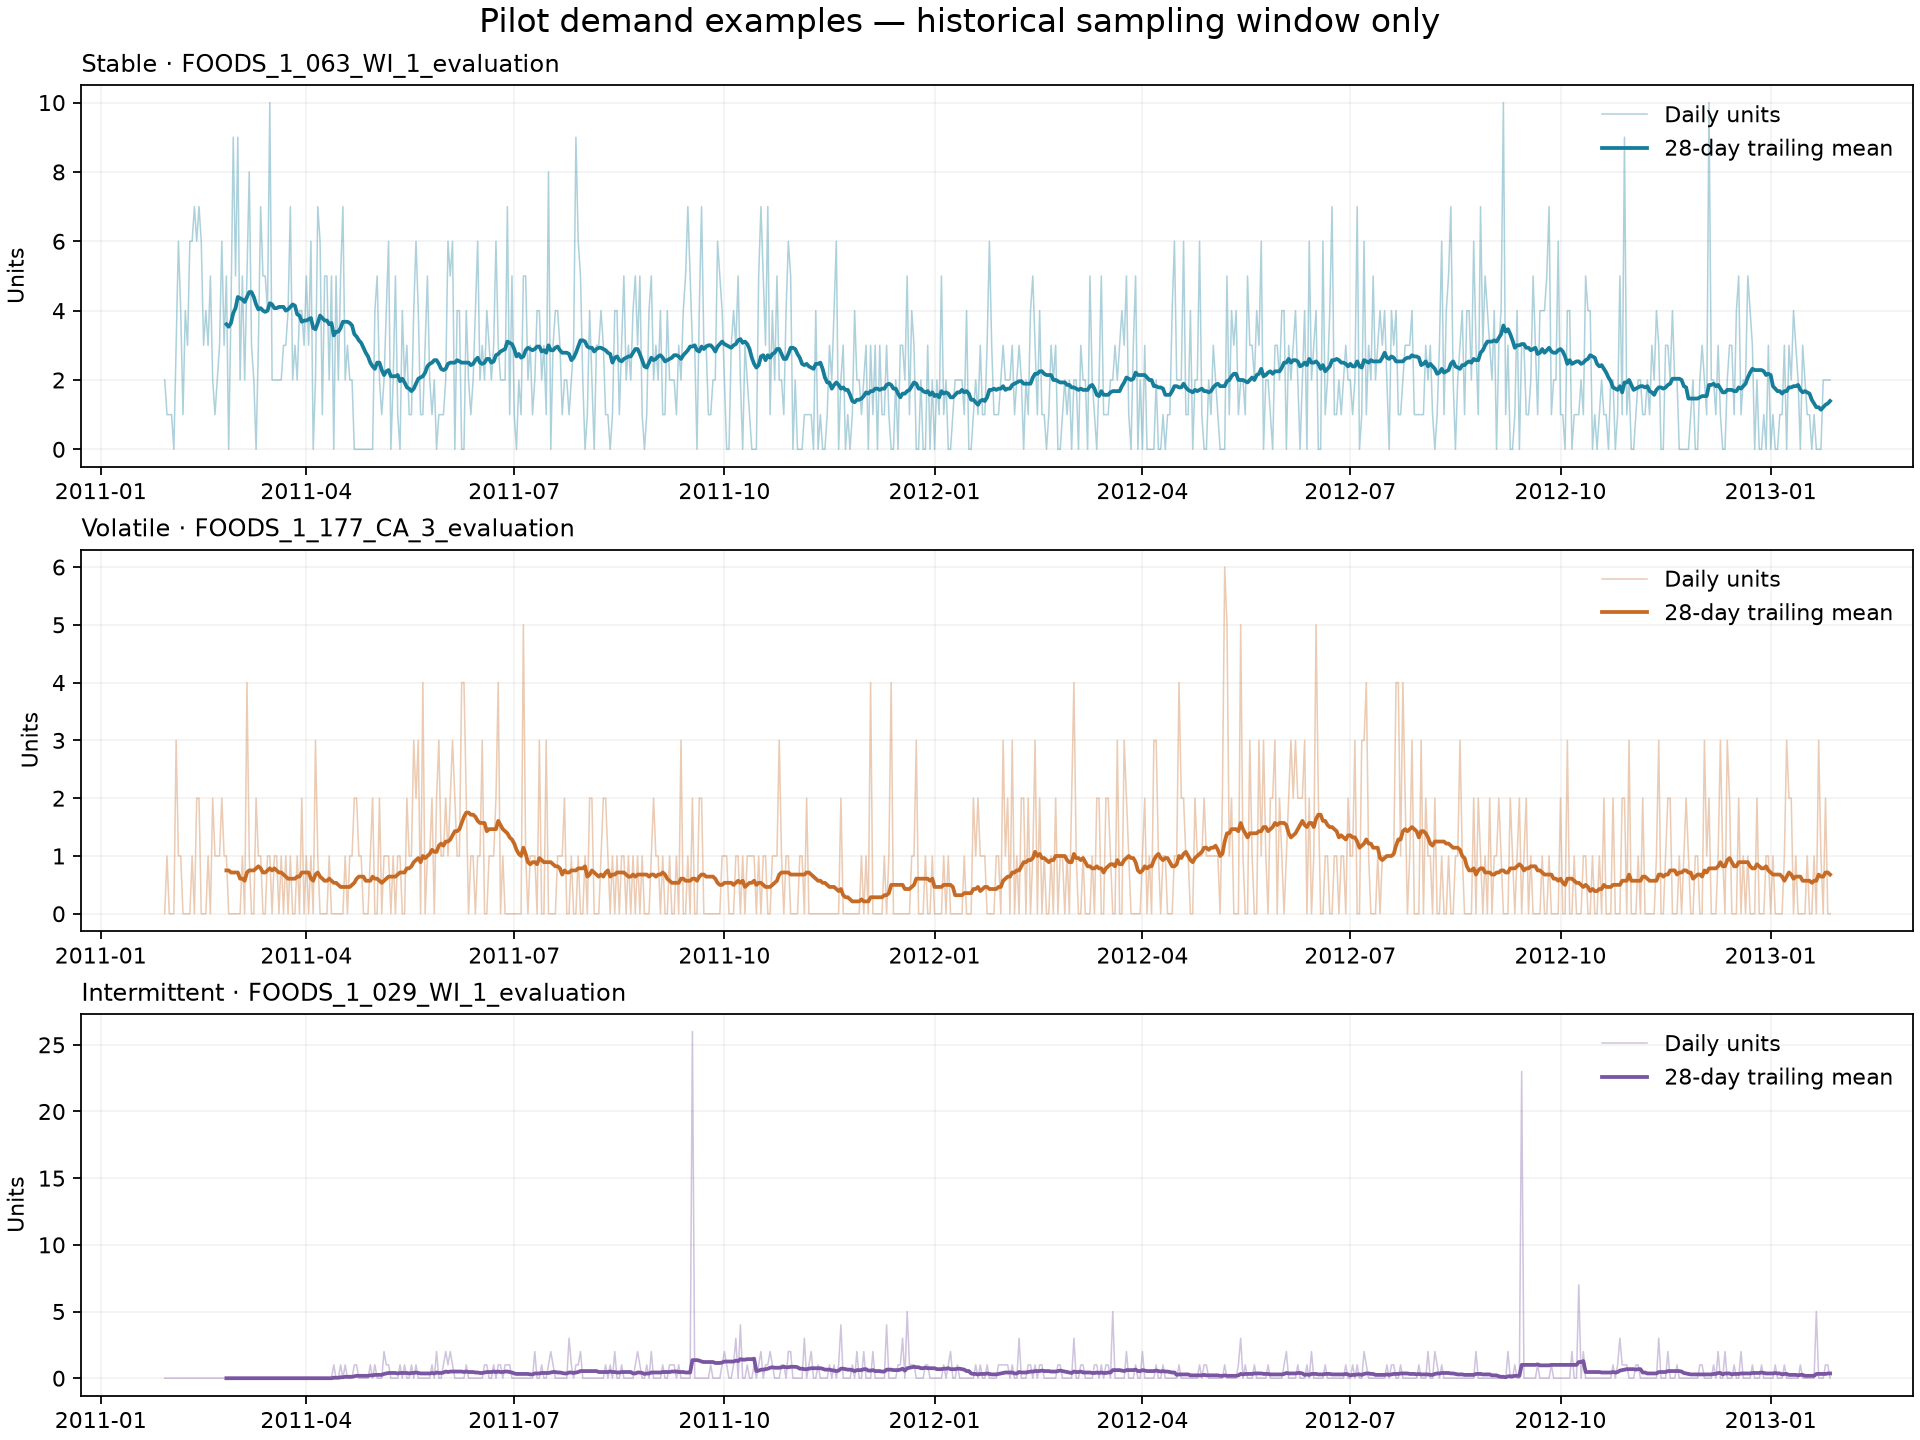

In [7]:
display(Image(filename=str(ROOT / "results/figures/representative_demand.png")))

### Dataset meanings and next stage
- Calendar: one row per day; `d` connects to sales and `wm_yr_wk` connects to weekly prices.
- Sales: one row per item/store, with daily unit counts in `d_*` columns.
- Prices: one row per item/store/week with an observed selling price.

Next: inspect `02_pilot_dataset.ipynb`. The reviewed core evaluation rules are locked in `docs/evaluation_protocol.md` (v1.0); model implementation has not started.